# Matplotlib : des graphiques ultra-nets avec une seule ligne

[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/moncoachdata/MonShotData/blob/main/Plotting/Matplotlib-Graphiques-Nets-SVG.ipynb)

📖 **Le shot complet** : [Rends tes graphiques Matplotlib ultra-nets avec une seule ligne de code](https://www.monshotdata.com/p/matplotlib-graphiques-nets-svg-jupyter)

---

Dans Jupyter, Matplotlib affiche par défaut tes graphiques en **PNG**, une image faite de pixels : dès que tu zoomes, elle devient floue. En demandant le format **SVG** (des formes vectorielles), le même graphique reste net à n'importe quel niveau de zoom. Une ligne suffit.

**À la fin de ce notebook, tu sauras :**

- pourquoi un graphique PNG devient flou quand on zoome, et pas un SVG ;
- deux façons d'activer le format SVG dans Jupyter : `%config` et `set_matplotlib_formats` ;
- comparer le poids d'un PNG et d'un SVG, pour savoir quand le SVG vaut le coup.

### Avant de lancer

- **Installation** : rien à installer sur Colab ou dans un environnement Jupyter classique : Matplotlib, NumPy et Seaborn y sont déjà.
- **Les données** : un échantillon tiré au hasard (graine fixée) dans la loi de Benford : on le génère dans le notebook.
- **Pour voir la différence** : après chaque graphique, **zoome dans la page** de ton navigateur (Ctrl et + ; Cmd et + sur Mac). Le PNG devient flou, le SVG reste net.

🧪 *Testé le 22 novembre 2026 : exécution complète de haut en bas (Python 3.13, Matplotlib 3.11, NumPy 2.5 et Seaborn 0.13). Les sorties affichées viennent de cette exécution.*

## 1. Mise en place

In [1]:
import io

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from matplotlib_inline.backend_inline import set_matplotlib_formats

sns.set_theme()   # le style par défaut de Seaborn, appliqué à tous les graphiques Matplotlib

In [2]:
def percent_formatter(x, pos):
    return f"{x*100:.0f}%"

colors = ['#46C7C7', '#00B9FF', '#FF7051', "orange", "darkorange", "tomato", "coral", "limegreen", "lightsalmon"]

## 2. Les données

On tire 10 000 premiers chiffres selon la **loi de Benford** (dans beaucoup de jeux de données réels, le chiffre 1 ouvre environ 30 % des nombres, le 2 environ 18 %, etc.), puis on calcule la fréquence de chaque chiffre.

In [3]:
rng = np.random.default_rng(42)   # graine fixée : on retrouve toujours le même échantillon

n_samples = 10000

# Probabilités de Benford : P(d) = log10(1 + 1/d)
digits = np.arange(1, 10)
probabilities = np.log10(1 + 1 / digits)

# Tire les premiers chiffres selon ces probabilités
first_digits = rng.choice(digits, size=n_samples, p=probabilities)

# Fréquence de chaque premier chiffre
frequency, _ = np.histogram(first_digits, bins=np.arange(1, 11))
frequency = frequency / frequency.sum()

print(np.round(frequency, 3))

[0.305 0.175 0.128 0.097 0.078 0.065 0.057 0.05  0.046]


Pour ne pas répéter le code du graphique à chaque essai, on le range dans une fonction :

In [4]:
def trace_benford():
    fig, ax = plt.subplots(figsize=(4, 2), facecolor="#f8fafc")

    ax.bar(digits, frequency, color=colors[8])
    ax.set_xlabel("Premier chiffre")
    ax.set_ylabel("Fréquence")
    ax.set_xticks(range(1, 10))
    ax.yaxis.set_major_formatter(mtick.FuncFormatter(percent_formatter))
    ax.set_title("Loi de Benford - Distribution du premier chiffre")

    plt.show()

## 3. Le rendu par défaut : PNG

Par défaut, Jupyter transforme la figure en image **PNG** avant de l'afficher. Une image PNG est une grille de pixels de taille fixe. Zoome dans la page : les bords des barres et le texte deviennent flous.

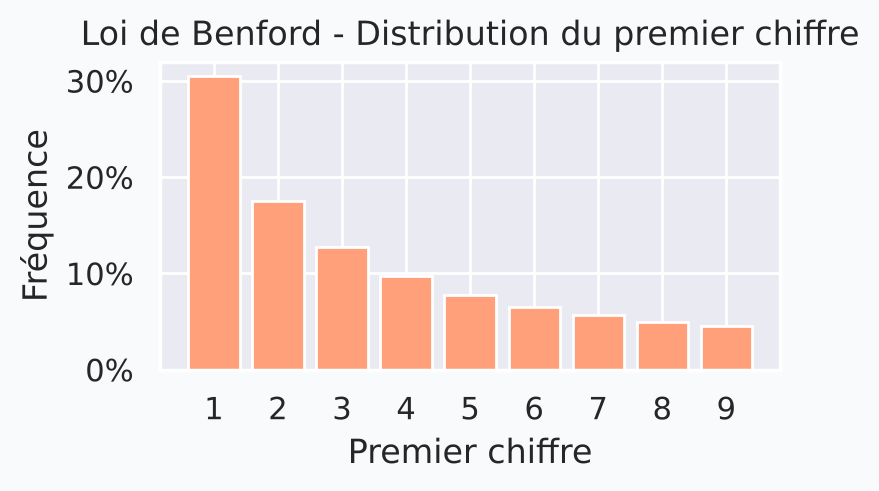

In [5]:
trace_benford()

## 4. Technique 1 : `%config InlineBackend.figure_format`

La *magic command* `%config` règle le backend « inline » de Jupyter (celui qui affiche les graphiques sous la cellule). Une ligne suffit pour passer en SVG, et elle vaut pour **tous** les graphiques suivants du notebook.

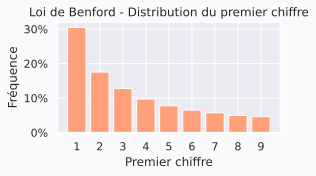

In [6]:
%config InlineBackend.figure_format = 'svg'

trace_benford()

Cette fois, le graphique est décrit par des **formes** (rectangles, lignes, texte) et non par des pixels. Zoome : tout reste net.

## 5. Technique 2 : `set_matplotlib_formats`

Même résultat, avec une fonction Python plutôt qu'une *magic command*. Elle est pratique dans un script ou une fonction, là où `%config` n'est pas disponible. Pour bien voir qu'elle fait le travail à elle seule, on repasse d'abord en PNG :

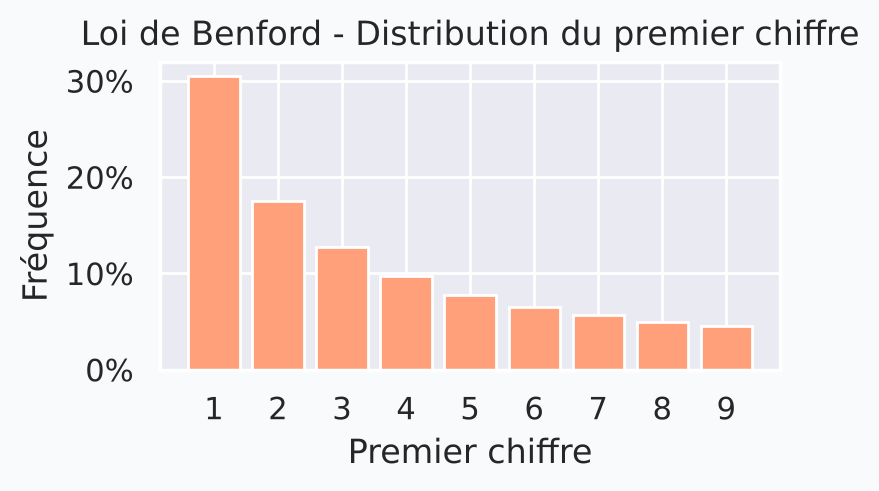

In [7]:
set_matplotlib_formats('png')   # retour au format par défaut
trace_benford()

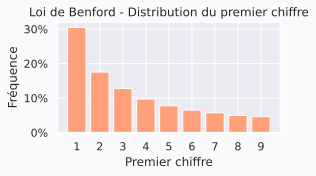

In [8]:
set_matplotlib_formats('svg')   # et c'est reparti en vectoriel
trace_benford()

Les deux techniques sont équivalentes : choisis celle que tu préfères.

## 6. PNG ou SVG : combien ça pèse ?

Un graphique SVG n'est pas toujours plus léger. On enregistre la même figure dans les deux formats (en mémoire) et on compare les tailles.

In [9]:
fig, ax = plt.subplots(figsize=(4, 2), facecolor="#f8fafc")
ax.bar(digits, frequency, color=colors[8])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(percent_formatter))
plt.close(fig)   # on ne l'affiche pas, on veut seulement la mesurer

for fmt in ["png", "svg"]:
    buffer = io.BytesIO()
    fig.savefig(buffer, format=fmt, facecolor=fig.get_facecolor())
    print(f"{fmt.upper()} : {len(buffer.getvalue()) / 1024:.1f} Ko")

PNG : 15.0 Ko
SVG : 12.3 Ko


Pour un graphique simple comme celui-ci, les deux formats ont un poids du même ordre (une quinzaine de Ko). Le SVG grossit avec le **nombre d'éléments** dessinés : un nuage de 100 000 points produit un SVG de plusieurs mégaoctets, qui ralentit le notebook, alors que le PNG garde la même taille. Voici le test :

In [10]:
rng2 = np.random.default_rng(0)
x, y = rng2.normal(size=(2, 20000))

fig, ax = plt.subplots(figsize=(4, 3))
ax.scatter(x, y, s=2)
plt.close(fig)

for fmt in ["png", "svg"]:
    buffer = io.BytesIO()
    fig.savefig(buffer, format=fmt)
    print(f"Nuage de 20 000 points, {fmt.upper()} : {len(buffer.getvalue()) / 1024:.0f} Ko")

Nuage de 20 000 points, PNG : 50 Ko


Nuage de 20 000 points, SVG : 2088 Ko


Règle pratique :

- **Graphiques simples** (barres, lignes, quelques centaines de points) : SVG, pour la netteté.
- **Très nombreux points** (nuages, heatmaps, images) : reste en PNG, plus léger et plus rapide à afficher.

## 7. Et pour enregistrer un fichier ?

`figure_format` ne règle que l'**affichage** dans le notebook. Pour exporter un fichier, choisis le format dans `savefig`, par l'extension du nom :

```python
fig.savefig("benford.svg")   # vectoriel, pour un site web, un rapport, une présentation
fig.savefig("benford.png", dpi=300)   # image, pour un document qui n'accepte pas le SVG
```

## 8. Ce qu'il faut retenir

- Jupyter affiche les graphiques Matplotlib en PNG (pixels) par défaut : ils deviennent flous quand on zoome.
- `%config InlineBackend.figure_format = 'svg'` bascule tout le notebook en vectoriel, en une ligne.
- `set_matplotlib_formats('svg')` (module `matplotlib_inline.backend_inline`) fait la même chose en Python ; `set_matplotlib_formats('png')` revient au défaut.
- Le poids d'un SVG grandit avec le nombre d'éléments dessinés : pour de très nombreux points, reste en PNG.
- Ce réglage ne concerne que l'affichage dans le notebook. Pour un fichier, choisis le format dans `savefig` (`.svg` ou `.png`).

---

## Pour aller plus loin

- [Rends tes tracés Matplotlib plus professionnels](https://www.monshotdata.com/p/rends-tes-traces-matplotlib-plus-professionnels) — pour des graphiques propres et lisibles
- [Style Matplotlib : rendre ses tracés plus attractifs](https://www.monshotdata.com/p/style-des-traces-matplotlib) — changer le style des tracés en une ligne
- [Tous les notebooks des shots](https://github.com/moncoachdata/MonShotData) — le code Python de la newsletter, rangé par thème